# BFP Intensity Extraction & gRNA Threshold Analysis — 4-Well Arsenite Experiment (15586-KL / 0617)

Extracts per-cell mean BFP intensity from the median-subtracted, stitched
BFP image, restricted to the 4 wells of interest (each independently
registered to the Xenium slide), then:

1. Saves per-cell BFP intensity (raw + log1p) to CSV.
2. Checks the intensity distributions.
3. Loads the CRISPRi sgRNA panel from `cell_feature_matrix.h5` and identifies
   any off-target/outlier gRNA by cell count.
4. Calls perturbation directly from `sgRNA_total_count > 1` (the threshold
   used throughout the rest of this project) and finds the best BFP+/BFP-
   intensity cutoff against that label via ROC/Youden's J.

**Channel correction:** this uses the **C1** channel as BFP (the C2-based runs in the sibling notebook without `_real` in the name used the wrong channel).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from skimage.draw import polygon
from scipy.sparse import issparse
from sklearn.metrics import roc_curve, auc

## Configuration

In [2]:
PROJECT_DIR = "path/to/project"
XENIUM_DIR = "path/to/xenium_output"
STITCHED_BFP_PATH = os.path.join(PROJECT_DIR, "BFP_0615_median_subtracted_real.npy")

PIXEL_SIZE_XENIUM = 0.2125  # um/px
FOV_SIZE = 2000
N_ROWS, N_COLS = 38, 18
OVERLAP_FRAC = 0.11
STEP = int(round(FOV_SIZE * (1 - OVERLAP_FRAC)))  # 1780

GRNA_COUNT_THRESHOLD = 1  # perturbed if raw guide count > 1 (>=2), matching every regression in this project
OUT_DIR = "."  # this notebook writes its own outputs here, never back into PROJECT_DIR

WELLS = {
    "top_left":     dict(rows=(2, 16),  cols=(2, 7),   affine_dir="lyso_top_left",               treatment="arsenite"),
    "top_right":    dict(rows=(2, 16),  cols=(12, 17), affine_dir="top_right_alignment_files",    treatment="arsenite"),
    "bottom_left":  dict(rows=(23, 37), cols=(2, 7),   affine_dir="bottom_left",                  treatment="untreated"),
    "bottom_right": dict(rows=(23, 37), cols=(12, 17), affine_dir="bottom_right_alignment_files", treatment="untreated"),
}

def well_pixel_bbox(well):
    r0, r1 = well["rows"]
    c0, c1 = well["cols"]
    x0 = (c0 - 1) * STEP
    x1 = (c1 - 1) * STEP + FOV_SIZE
    y0 = (r0 - 1) * STEP
    y1 = (r1 - 1) * STEP + FOV_SIZE
    return x0, x1, y0, y1

for name, w in WELLS.items():
    print(name, "pixel bbox (x0,x1,y0,y1):", well_pixel_bbox(w))

top_left pixel bbox (x0,x1,y0,y1): (1780, 12680, 1780, 28700)
top_right pixel bbox (x0,x1,y0,y1): (19580, 30480, 1780, 28700)
bottom_left pixel bbox (x0,x1,y0,y1): (1780, 12680, 39160, 66080)
bottom_right pixel bbox (x0,x1,y0,y1): (19580, 30480, 39160, 66080)


## Step 1 — Load the stitched BFP image and Xenium cell boundaries

In [3]:
out_csv = os.path.join(PROJECT_DIR, "bfp_intensity_per_cell_median_subtracted_real.csv")
NEED_EXTRACTION = not os.path.exists(out_csv)

if NEED_EXTRACTION:
    stitched_image = np.load(STITCHED_BFP_PATH, mmap_mode="r")  # mmap: a full in-RAM load OOMs this host
    print("stitched_image shape:", stitched_image.shape, "dtype:", stitched_image.dtype)

    cell_boundaries_csv = pd.read_csv(os.path.join(XENIUM_DIR, "cell_boundaries.csv.gz"))
    print(f"Loaded {len(cell_boundaries_csv)} boundary vertices, "
          f"{cell_boundaries_csv['cell_id'].nunique()} unique cells")
else:
    print(f"Found existing {out_csv} -- skipping image load + extraction.")

Found existing /nfs/turbo/umms-welchjd-code/code/mingjiay/Xenium_0617_Lyso_verify/bfp_intensity_per_cell_median_subtracted_real.csv -- skipping image load + extraction.


## Step 2 — Per-well affine transform + per-cell mean BFP intensity

- Convert cell boundary vertices from um to Xenium pixel space (`/0.2125`).
- Apply the well's inverse affine matrix to project into that well's CQ1/lyso
  pixel space — the same coordinate system as the stitched BFP image.
- Keep only cells whose transformed bounding box falls fully inside that
  well's pixel region.
- Rasterize each cell's polygon and take the mean pixel value from the
  stitched BFP image.

In [4]:
def transform_cell_boundaries(affine_dir):
    matrix = np.loadtxt(os.path.join(PROJECT_DIR, affine_dir, "matrix.csv"), delimiter=",")
    matrix_inv = np.linalg.inv(matrix)

    df = cell_boundaries_csv.copy()
    df["vertex_x_coord"] = df["vertex_x"] / PIXEL_SIZE_XENIUM
    df["vertex_y_coord"] = df["vertex_y"] / PIXEL_SIZE_XENIUM

    homogeneous = np.hstack([
        df[["vertex_x_coord", "vertex_y_coord"]].values,
        np.ones((df.shape[0], 1)),
    ])
    transformed = homogeneous.dot(matrix_inv.T)
    df["x_transformed"] = np.round(transformed[:, 0]).astype(int)
    df["y_transformed"] = np.round(transformed[:, 1]).astype(int)
    return df


def extract_well_intensities(well_name, well):
    df = transform_cell_boundaries(well["affine_dir"])
    x0, x1, y0, y1 = well_pixel_bbox(well)

    agg = df.groupby("cell_id").agg(
        x_min=("x_transformed", "min"), x_max=("x_transformed", "max"),
        y_min=("y_transformed", "min"), y_max=("y_transformed", "max"),
    )
    valid_ids = agg[
        (agg["x_min"] >= x0) & (agg["x_max"] < x1) &
        (agg["y_min"] >= y0) & (agg["y_max"] < y1)
    ].index

    df_well = df[df["cell_id"].isin(valid_ids)]

    cell_ids, mean_intensities = [], []
    for cell_id, grp in df_well.groupby("cell_id"):
        xs = grp["x_transformed"].to_numpy()
        ys = grp["y_transformed"].to_numpy()
        rr, cc = polygon(ys, xs, stitched_image.shape)
        if len(rr) == 0:
            continue
        cell_ids.append(cell_id)
        mean_intensities.append(stitched_image[rr, cc].mean())

    result = pd.DataFrame({
        "cell_id": cell_ids,
        "mean_intensity": mean_intensities,
        "well": well_name,
        "treatment": well["treatment"],
    })
    print(f"[{well_name}] {len(valid_ids)} cells in well bbox, {len(result)} with valid polygons")
    return result

if NEED_EXTRACTION:
    well_results = [extract_well_intensities(name, w) for name, w in WELLS.items()]
    intensity_df = pd.concat(well_results, ignore_index=True)
    print(f"\nTotal cells across all 4 wells: {len(intensity_df)}")
    print(intensity_df["well"].value_counts())
else:
    intensity_df = pd.read_csv(out_csv)
    print(f"Loaded {len(intensity_df)} rows from {out_csv}")
    print(intensity_df["well"].value_counts())

Loaded 141929 rows from /nfs/turbo/umms-welchjd-code/code/mingjiay/Xenium_0617_Lyso_verify/bfp_intensity_per_cell_median_subtracted_real.csv
well
bottom_left     40457
top_left        38078
bottom_right    33954
top_right       29440
Name: count, dtype: int64


## Step 3 — NaN check, log1p transform, save to CSV

In [5]:
if NEED_EXTRACTION:
    n_nan = intensity_df["mean_intensity"].isna().sum()
    print(f"NaN mean intensities: {n_nan}")
    intensity_df = intensity_df.dropna(subset=["mean_intensity"]).reset_index(drop=True)
    intensity_df["log_mean_intensity"] = np.log1p(intensity_df["mean_intensity"])

    import anndata as ad
    lyso_adata = ad.read_h5ad(os.path.join(PROJECT_DIR, "lyso_final_clusters.h5ad"), backed="r")
    lyso_cell_ids = set(lyso_adata.obs_names)
    print(f"lyso_final_clusters.h5ad: {len(lyso_cell_ids)} cells")

    intensity_df["in_lyso_final_clusters"] = intensity_df["cell_id"].isin(lyso_cell_ids)
    overlap_rows = []
    for name in WELLS:
        well_ids = set(intensity_df.loc[intensity_df["well"] == name, "cell_id"])
        n_overlap = len(well_ids & lyso_cell_ids)
        overlap_rows.append(dict(well=name, n_well_cells=len(well_ids), n_overlap_with_lyso=n_overlap))
        print(f"[{name}] {len(well_ids)} cells in well, {n_overlap} overlap with lyso_final_clusters.h5ad")
    all_ids = set(intensity_df["cell_id"])
    n_all_overlap = len(all_ids & lyso_cell_ids)
    overlap_rows.append(dict(well="ALL", n_well_cells=len(all_ids), n_overlap_with_lyso=n_all_overlap))
    print(f"[ALL] {len(all_ids)} cells across all wells, {n_all_overlap} overlap with lyso_final_clusters.h5ad")
    overlap_df = pd.DataFrame(overlap_rows)
    overlap_df.to_csv(os.path.join(PROJECT_DIR, "bfp_wells_lyso_overlap_median_subtracted_real.csv"), index=False)

    intensity_df[["cell_id", "mean_intensity", "log_mean_intensity", "well", "treatment", "in_lyso_final_clusters"]].to_csv(out_csv, index=False)
    print(f"Saved {len(intensity_df)} rows to {out_csv}")
else:
    print(f"Using cached intensity_df ({len(intensity_df)} rows) -- extraction + lyso overlap already computed previously.")
    print(pd.read_csv(os.path.join(PROJECT_DIR, "bfp_wells_lyso_overlap_median_subtracted_real.csv")))

intensity_df.head()

Using cached intensity_df (141929 rows) -- extraction + lyso overlap already computed previously.
           well  n_well_cells  n_overlap_with_lyso
0      top_left         38078                17659
1     top_right         29440                10475
2   bottom_left         40457                15510
3  bottom_right         33954                12137
4           ALL        141929                55781


,cell_id,mean_intensity,log_mean_intensity,well,treatment,in_lyso_final_clusters
0,aaacfipg-1,2.486333,1.248850,top_left,arsenite,False
1,aaaehkeo-1,24.236212,3.228280,top_left,arsenite,True
2,aaaencgj-1,1.841163,1.044214,top_left,arsenite,True
3,aaaffken-1,9.073529,2.309911,top_left,arsenite,True
4,aaaflbcf-1,2.400387,1.223889,top_left,arsenite,True


## Step 4 — Distribution of BFP intensity (raw and log1p)

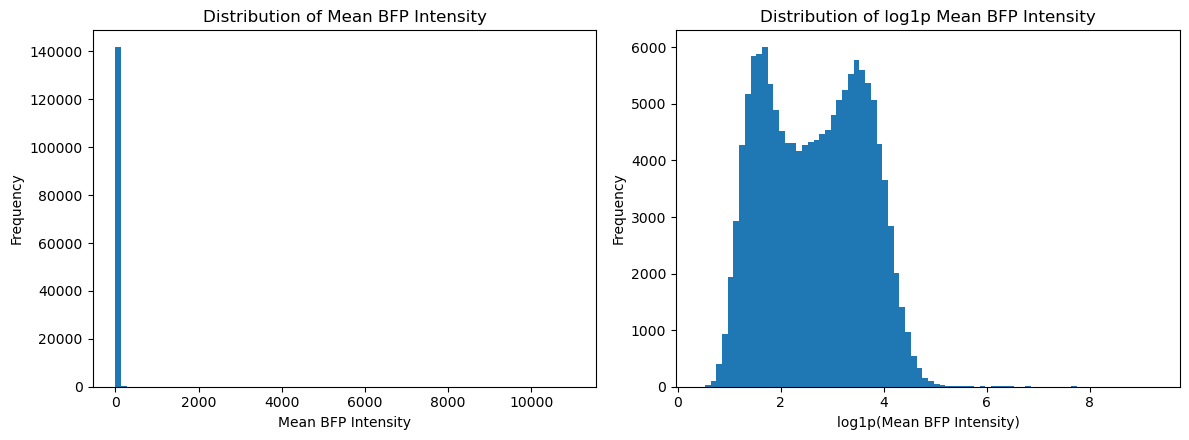

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(intensity_df["mean_intensity"], bins=80)
axes[0].set_xlabel("Mean BFP Intensity")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Mean BFP Intensity")

axes[1].hist(intensity_df["log_mean_intensity"], bins=80)
axes[1].set_xlabel("log1p(Mean BFP Intensity)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of log1p Mean BFP Intensity")

plt.tight_layout()
plt.show()

## Step 5 — Load gRNA (sgRNA) data

`cell_feature_matrix.h5` lives in the same Xenium output folder as
`cell_boundaries.csv.gz`. sgRNA genes are identified as `var_names`
containing a hyphen (the `GENE-N` guide-naming convention), excluding `HLA`
genes (which also contain hyphens but aren't guides).

In [7]:
adata = sc.read_10x_h5(os.path.join(XENIUM_DIR, "cell_feature_matrix.h5"))
adata.obs["total_counts"] = adata.X.sum(axis=1).A1
print("Total cells:", adata.n_obs)

adata_filtered = adata.copy()
print("Using all cells (no RNA total-count filter):", adata_filtered.n_obs)

sgRNA_genes = [g for g in adata_filtered.var_names if "-" in g and "HLA" not in g]
print("sgRNA genes:", len(sgRNA_genes))

Total cells: 150377
Using all cells (no RNA total-count filter): 150377
sgRNA genes: 122


## Step 6 — Identify off-target/outlier gRNA by cell count

Computed at the same `count > 1` threshold used for perturbation calling
below, not a fixed `>0` -- off-target status should reflect the population
actually being analyzed.

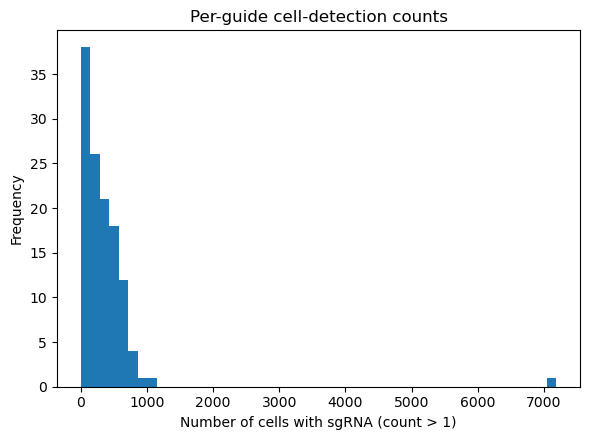

Top 10 guides by cell count:
     gene  count  modified_zscore
   SOX5-3   7187        23.835208
   BNC2-1   1051         2.665224
   JUNB-4   1000         2.489267
    ID2-4    857         1.995899
   AFF1-2    803         1.809592
ONECUT1-4    755         1.643986
   KLF3-3    744         1.606035
   EBF3-1    701         1.457679
   NFIB-2    690         1.419728
ONECUT1-3    674         1.364526

Outliers (modified z > 3.5):
  gene  count  modified_zscore
SOX5-3   7187        23.835208

Excluding as off-target: ['SOX5-3']


In [8]:
idxs = [adata_filtered.var_names.get_loc(g) for g in sgRNA_genes]
mat = adata_filtered.X[:, idxs]
if issparse(mat):
    mat = mat.toarray()
bin_mat = (mat > GRNA_COUNT_THRESHOLD).astype(int)

counts = pd.Series(bin_mat.sum(axis=0), index=sgRNA_genes).sort_values(ascending=False)
counts_df = pd.DataFrame({"gene": counts.index, "count": counts.values})

median_c = counts_df["count"].median()
mad = (counts_df["count"] - median_c).abs().median()
counts_df["modified_zscore"] = 0.6745 * (counts_df["count"] - median_c) / mad
MODIFIED_Z_CUTOFF = 3.5
outliers = counts_df[counts_df["modified_zscore"] > MODIFIED_Z_CUTOFF].sort_values("modified_zscore", ascending=False)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.hist(counts_df["count"], bins=50)
ax.set_xlabel(f"Number of cells with sgRNA (count > {GRNA_COUNT_THRESHOLD})")
ax.set_ylabel("Frequency")
ax.set_title("Per-guide cell-detection counts")
plt.tight_layout()
plt.show()

print("Top 10 guides by cell count:")
print(counts_df.sort_values("count", ascending=False).head(10).to_string(index=False))
print(f"\nOutliers (modified z > {MODIFIED_Z_CUTOFF}):")
print(outliers.to_string(index=False))

OFF_TARGET_GENES = outliers["gene"].tolist()
print(f"\nExcluding as off-target: {OFF_TARGET_GENES}")

## Step 7 — sgRNA-based perturbation calls (excluding off-target gRNA, count > 1)

In [9]:
remaining = [g for g in sgRNA_genes if g not in OFF_TARGET_GENES]
remaining_idxs = [adata_filtered.var_names.get_loc(g) for g in remaining]
mat_remain = adata_filtered.X[:, remaining_idxs]
if issparse(mat_remain):
    mat_remain = mat_remain.toarray()

bin_remain = (mat_remain > GRNA_COUNT_THRESHOLD).astype(int)
adata_filtered.obs["sgRNA_Gene_count"] = bin_remain.sum(axis=1)
adata_filtered.obs["sgRNA_total_count"] = mat_remain.sum(axis=1)
adata_filtered.obs["perturbation"] = np.where(
    adata_filtered.obs["sgRNA_total_count"] > GRNA_COUNT_THRESHOLD, "perturbed", "unperturbed"
)

print(adata_filtered.obs[["sgRNA_Gene_count", "sgRNA_total_count"]].describe())
print()
print(adata_filtered.obs["perturbation"].value_counts())

       sgRNA_Gene_count  sgRNA_total_count
count     150377.000000      150377.000000
mean           0.251561           2.858649
std            0.455899           6.466017
min            0.000000           0.000000
25%            0.000000           0.000000
50%            0.000000           0.000000
75%            0.000000           2.000000
max            4.000000          79.000000

perturbation
unperturbed    104948
perturbed       45429
Name: count, dtype: int64


## Step 8 — Merge gRNA calls with BFP intensity

In [10]:
gRNA_df = adata_filtered.obs[["sgRNA_Gene_count", "sgRNA_total_count", "perturbation"]].copy()
merged = intensity_df.set_index("cell_id").join(gRNA_df, how="inner")
print(f"Cells with both BFP intensity and gRNA data: {len(merged)}")
merged.to_csv(os.path.join(OUT_DIR, "bfp_intensity_with_gRNA.csv"))
merged.head()

Cells with both BFP intensity and gRNA data: 141929


,mean_intensity,log_mean_intensity,well,treatment,in_lyso_final_clusters,sgRNA_Gene_count,sgRNA_total_count,perturbation
aaacfipg-1,2.486333,1.248850,top_left,arsenite,False,0,0.0,unperturbed
aaaehkeo-1,24.236212,3.228280,top_left,arsenite,True,0,0.0,unperturbed
aaaencgj-1,1.841163,1.044214,top_left,arsenite,True,0,0.0,unperturbed
aaaffken-1,9.073529,2.309911,top_left,arsenite,True,0,0.0,unperturbed
aaaflbcf-1,2.400387,1.223889,top_left,arsenite,True,0,0.0,unperturbed


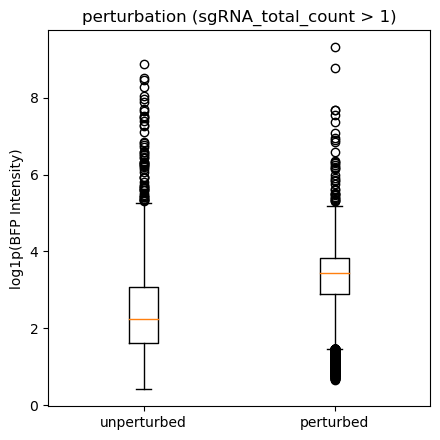

In [11]:
clean = merged[["perturbation", "log_mean_intensity"]].dropna()
g_un = clean.loc[clean["perturbation"] == "unperturbed", "log_mean_intensity"]
g_pe = clean.loc[clean["perturbation"] == "perturbed", "log_mean_intensity"]

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.boxplot([g_un, g_pe], labels=["unperturbed", "perturbed"])
ax.set_title(f"perturbation (sgRNA_total_count > {GRNA_COUNT_THRESHOLD})")
ax.set_ylabel("log1p(BFP Intensity)")
plt.tight_layout()
plt.show()

## Step 9 — Best BFP+/BFP- cutoff (direct ROC, `sgRNA_total_count > 1` as ground truth)

Treat the `perturbation` label defined above (`sgRNA_total_count > 1`) as
ground truth, and find the BFP log-intensity threshold that best separates
perturbed from unperturbed cells via Youden's J statistic on the ROC curve.

n=141929, perturbed=43390, unperturbed=98539
AUC=0.7794, cutoff=2.8082, sensitivity=0.7745, specificity=0.6752


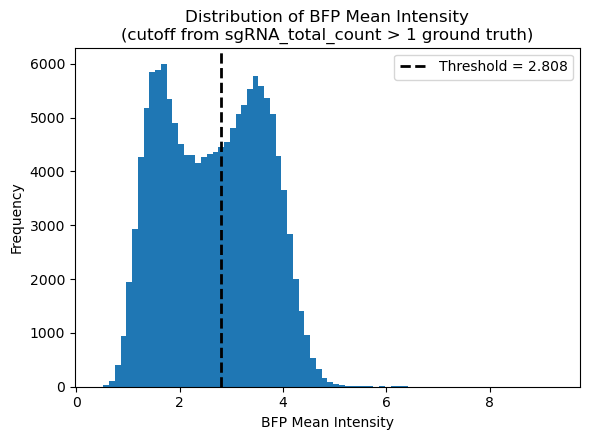

In [12]:
clean = merged[["perturbation", "log_mean_intensity"]].dropna()
y_true = (clean["perturbation"] == "perturbed").astype(int).values
scores = clean["log_mean_intensity"].values

fpr, tpr, thresholds = roc_curve(y_true, scores)
roc_auc = auc(fpr, tpr)
specificity = 1 - fpr
j = tpr - fpr
idx = np.argmax(j)
cutoff, sens, spec = thresholds[idx], tpr[idx], specificity[idx]

print(f"n={len(clean)}, perturbed={y_true.sum()}, unperturbed={(1 - y_true).sum()}")
print(f"AUC={roc_auc:.4f}, cutoff={cutoff:.4f}, sensitivity={sens:.4f}, specificity={spec:.4f}")

fig = plt.figure(figsize=(6, 4.5))
plt.hist(merged["log_mean_intensity"].dropna(), bins=80)
plt.axvline(x=cutoff, color="black", linestyle="--", linewidth=2, label=f"Threshold = {cutoff:.3f}")
plt.xlabel("BFP Mean Intensity")
plt.ylabel("Frequency")
plt.title("Distribution of BFP Mean Intensity\n(cutoff from sgRNA_total_count > 1 ground truth)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "bfp_intensity_histogram_best_cutoff.png"), dpi=150, bbox_inches="tight")
plt.show()

## Summary

- Extracted mean BFP intensity for every cell in the 4 wells of interest
  (per-well affine transform), saved to `bfp_intensity_per_cell_median_subtracted_real.csv`.
- Loaded the CRISPRi sgRNA panel (122 guides) from `cell_feature_matrix.h5`,
  using all cells (no RNA total-count filter).
- Identified off-target gRNA by modified z-score on per-guide cell counts, computed
  at the same `count > 1` threshold used for perturbation calling.
- Called perturbation directly from `sgRNA_total_count > 1` and found the best
  BFP+/BFP- intensity cutoff against that label via direct ROC/Youden's J.
- Full merged table (`bfp_intensity_with_gRNA_median_subtracted_real.csv`) saved
  for downstream use.